In [83]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from build_lagged_features import read_table, build_lagged_frame
import matplotlib.pyplot as plt

## Vår första, väldigt simpla modell för att jämföra hur bra alla ändringar blir. Den är utan data pre-processing och validerings steget

## Testa leka med datan

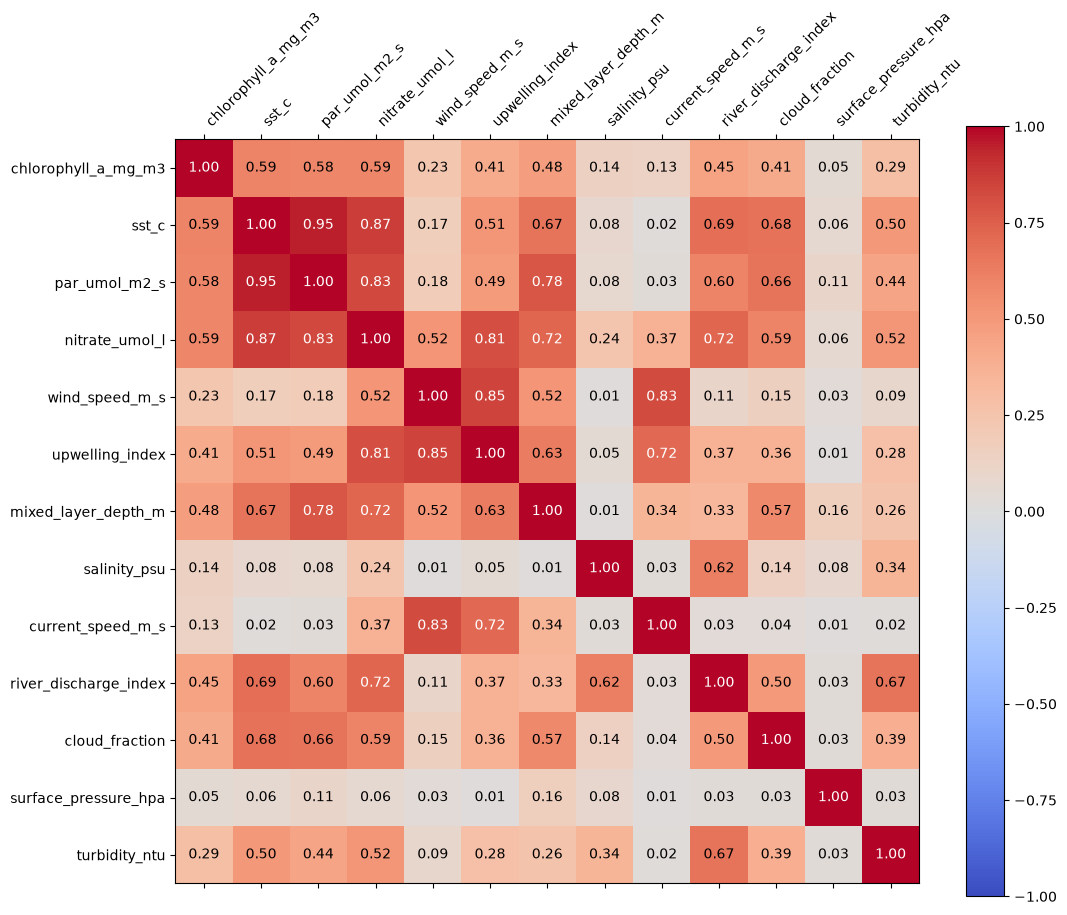

In [84]:
raw = read_table("chlorophyll_student_2015_2023.xlsx") # import raw data
train_start = '2015-01-01' # Change later to final
train_end = '2019-12-31'

train_dates = (raw['date'] >= train_start) & (raw['date'] <= train_end)
corr_matrix = raw[train_dates].corr(numeric_only=True).abs()

# heatmap plott
fig, ax = plt.subplots(figsize=(12, 10)) # Gjorde figuren lite större för att få plats med texten
cax = ax.matshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)

fig.colorbar(cax)

ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha='left') 
ax.set_yticklabels(corr_matrix.columns)

# Loop through each cell and write out the number
for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        value = corr_matrix.iloc[i, j]
        
        text_color = "white" if abs(value) > 0.7 else "black"
        
        ax.text(j, i, f"{value:.2f}", 
                ha="center", va="center", color=text_color, fontsize=10)

plt.show()

## Hantera datan och sortera

In [85]:
raw = read_table("chlorophyll_student_2015_2023.xlsx") # import raw data
df_lagged = build_lagged_frame(raw) # Assign to df

# Make sure its the right dtype
df_lagged["date"] = pd.to_datetime(df_lagged["date"])
df_lagged = df_lagged.sort_values(by = "date").set_index("date")

# Target variable: clorofyll
chlorophyll = 'chlorophyll_a_mg_m3'
Y = df_lagged[chlorophyll] # includes all lagged clorophyll variables except 0

# Features: all other variables except chlorophyll
X = df_lagged.drop(columns = [chlorophyll]) # removes all lagged clorophyll variables from the features

# lägg tillvalidering data

# Divide into training and test data based on dates 
train_start = '2015-01-15' 
train_end = '2019-12-31'

test_start = '2020-01-01'
test_end = '2023-12-31'

# Finally the training and test data (vector and matrix)
X_train = X.loc[train_start:train_end]
X_test = X.loc[test_start:test_end]

Y_train = Y.loc[train_start:train_end]
Y_test = Y.loc[test_start:test_end]

# Normalizing only the test data to avoid data leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [86]:
# Linjär regressionmodell
model_LR = LinearRegression()
model_LR.fit(X_train_scaled, Y_train)

y_predict_LR = model_LR.predict(X_test_scaled)
R2_LR = r2_score(Y_test, y_predict_LR)
rmse_LR = np.sqrt(mean_squared_error(Y_test, y_predict_LR))
mae_LR = mean_absolute_error(Y_test, y_predict_LR)

print(f"R2 for Linear Regression: {R2_LR}")
print(f"RMSE for Linear Regression: {rmse_LR}")
print(f"MAE for Linear Regression: {mae_LR}")



R2 for Linear Regression: 0.6578945816335986
RMSE for Linear Regression: 0.38794373333707965
MAE for Linear Regression: 0.2051166882567842


In [87]:
# Ridge regressionmodell

model_ridge = Ridge(alpha=1.0) # alpha är samma som lambda
model_ridge.fit(X_train_scaled, Y_train)

y_predict_ridge = model_ridge.predict(X_test_scaled)
R2_ridge = r2_score(Y_test, y_predict_ridge)
mae_ridge = mean_absolute_error(Y_test, y_predict_ridge)
rmse_ridge = np.sqrt(mean_squared_error(Y_test, y_predict_ridge))

print(f"R2 for Ridge Regression: {R2_ridge}")
print(f"RMSE for Ridge Regression: {rmse_ridge}")
print(f"MAE for Ridge Regression: {mae_ridge}")


R2 for Ridge Regression: 0.6582969516653953
RMSE for Ridge Regression: 0.3877155246481609
MAE for Ridge Regression: 0.20486985909997724


In [88]:
# Lasso regressionmodell

model_lasso = Lasso(alpha=0.1)
model_lasso.fit(X_train_scaled, Y_train)

y_predict_lasso = model_lasso.predict(X_test_scaled)
R2_lasso = r2_score(Y_test, y_predict_lasso)
rmse_lasso = np.sqrt(mean_squared_error(Y_test, y_predict_lasso))
mae_lasso = mean_absolute_error(Y_test, y_predict_lasso)

print(f"R2 for Lasso Regression: {R2_lasso}")
print(f"RMSE for Lasso Regression: {rmse_lasso}")
print(f"MAE for Lasso Regression: {mae_lasso}")



R2 for Lasso Regression: 0.6227049600235902
RMSE for Lasso Regression: 0.40740777462369593
MAE for Lasso Regression: 0.22570811691016893


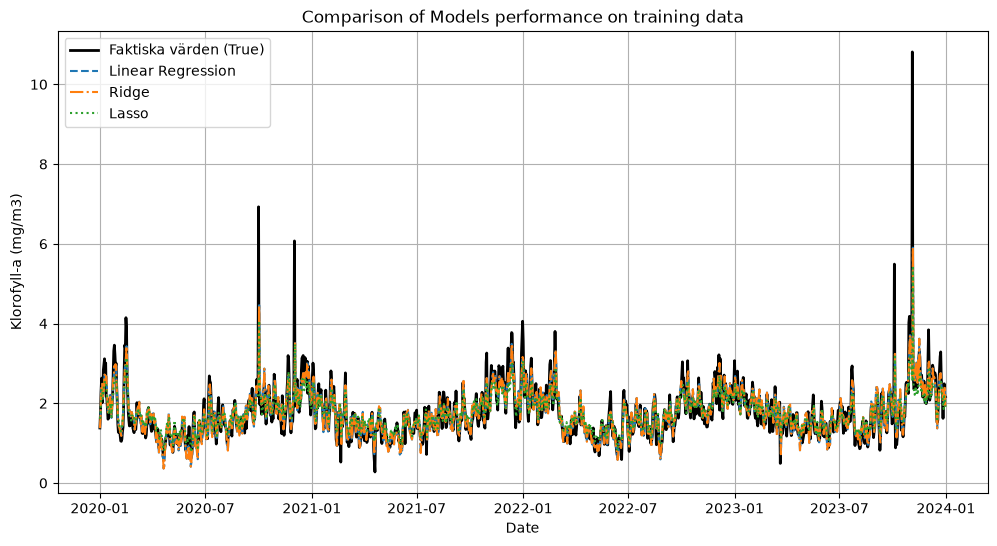

In [89]:
# Skapa en figur
plt.figure(figsize=(12, 6))

# Plotta de faktiska värdena (svart linje)
plt.plot(Y_test.index, Y_test, label='Faktiska värden (True)', color='black', linewidth=2)

# Plotta modellernas prediktioner
plt.plot(Y_test.index, y_predict_LR, label='Linear Regression', linestyle='--')
plt.plot(Y_test.index, y_predict_ridge, label='Ridge', linestyle='-.')
plt.plot(Y_test.index, y_predict_lasso, label='Lasso', linestyle=':')

# Formatera grafen
plt.xlabel('Date')
plt.ylabel('Klorofyll-a (mg/m3)')
plt.title('Comparison of Models performance on training data')
plt.legend()
plt.grid(True)
plt.show()